# Model Predictive Control for Cooling Distribution Units

We divide the liquid-cooled rack and CDU secondary loop into two well-mixed thermal control volumes with uniform lumped temperatures:

#### Control Volume 1 — Silicon Chips & Cold Plates ($T_{\text{chip}}$)
Heat enters via electrical IT power dissipation $Q_{\text{IT}}(t)$ (in $\text{kW}$) and leaves by conduction/convection into the secondary coolant across an effective thermal resistance $R_{\text{th}}$ (in $\text{K/kW}$). Applying conservation of energy with effective thermal capacitance $C_{\text{chip}}$ (in $\text{kJ/K}$):

$$C_{\text{chip}} \frac{dT_{\text{chip}}}{dt} = Q_{\text{IT}}(t) - \frac{T_{\text{chip}}(t) - T_{\text{cdu}}(t)}{R_{\text{th}}}$$


#### Control Volume 2 — CDU Secondary Coolant Loop ($T_{\text{cdu}}$)
Heat enters from the cold plates and is rejected across the CDU liquid-to-liquid heat exchanger to the facility chilled-water loop at supply temperature $T_{\text{fac}}$. Assuming an ideal heat exchanger effectiveness ($\varepsilon \approx 1$) or lumping heat-exchanger effectiveness into $T_{\text{fac}}$, the advective heat removal rate is $\dot{m}(t)\,c_p\left(T_{\text{cdu}}(t) - T_{\text{fac}}\right)$, where $\dot{m}(t)$ is the pump mass flow rate ($\text{kg/s}$) and $c_p$ is the specific heat capacity ($\text{kJ/(kg}\cdot\text{K)}$):

$$C_{\text{cdu}} \frac{dT_{\text{cdu}}}{dt} = \frac{T_{\text{chip}}(t) - T_{\text{cdu}}(t)}{R_{\text{th}}} - \dot{m}(t)\,c_p\left(T_{\text{cdu}}(t) - T_{\text{fac}}\right)$$

To initialize the simulation at idle equilibrium ($\frac{dT_{\text{chip}}}{dt} = \frac{dT_{\text{cdu}}}{dt} = 0$) for a given idle load $Q_{\text{IT},0}$ and pump flow $\dot{m}_0$, adding the two equations eliminates the internal heat-transfer term and yields:

$$T_{\text{cdu},0} = T_{\text{fac}} + \frac{Q_{\text{IT},0}}{\dot{m}_0 c_p}, \qquad T_{\text{chip},0} = T_{\text{cdu},0} + Q_{\text{IT},0} R_{\text{th}}$$

Define the state vector $\mathbf{x} \in \mathbb{R}^2$, manipulated variable $u \in \mathbb{R}$, and measured disturbance $d \in \mathbb{R}$:


$$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix} = \begin{bmatrix} T_{\text{chip}} \\ T_{\text{cdu}} \end{bmatrix}, \qquad u = \dot{m}, \qquad d = Q_{\text{IT}}$$

Dividing each ODE by its respective thermal capacitance gives the continuous-time nonlinear state equations $\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}, u, d)$:


$$\begin{aligned} f_1(\mathbf{x}, u, d) &= -\frac{1}{C_{\text{chip}} R_{\text{th}}} x_1 + \frac{1}{C_{\text{chip}} R_{\text{th}}} x_2 + \frac{1}{C_{\text{chip}}} d \\ f_2(\mathbf{x}, u, d) &= \frac{1}{C_{\text{cdu}} R_{\text{th}}} x_1 - \frac{1}{C_{\text{cdu}} R_{\text{th}}} x_2 - \frac{c_p}{C_{\text{cdu}}}\, u\,(x_2 - T_{\text{fac}}) \end{aligned}$$

Notice that $f_1$ is strictly linear, whereas $f_2$ contains the **bilinear product** $u \cdot x_2$ (mass flow multiplying coolant temperature). Because the convective cooling gain depends on the current coolant temperature, a single fixed linear model loses accuracy across large temperature swings.

At each control step $k$, we linearize $\mathbf{f}(\mathbf{x}, u, d)$ around the current operating point $(\mathbf{x}_0, u_0, d_0) = (\mathbf{x}_k, u_{k-1}, d_k)$ using a first-order multivariable Taylor expansion:


$$\dot{\mathbf{x}} \approx \mathbf{f}(\mathbf{x}_0, u_0, d_0) + \underbrace{\left.\frac{\partial \mathbf{f}}{\partial \mathbf{x}}\right\vert{}_0}_{A_c} (\mathbf{x} - \mathbf{x}_0) + \underbrace{\left.\frac{\partial \mathbf{f}}{\partial u}\right\vert{}_0}_{\mathbf{B}_u} (u - u_0) + \underbrace{\left.\frac{\partial \mathbf{f}}{\partial d}\right\vert{}_0}_{\mathbf{B}_d} (d - d_0)$$

#### State Jacobian ($A_c \in \mathbb{R}^{2 \times 2}$)

$$A_c = \begin{bmatrix} \dfrac{\partial f_1}{\partial x_1} & \dfrac{\partial f_1}{\partial x_2} \\ \dfrac{\partial f_2}{\partial x_1} & \dfrac{\partial f_2}{\partial x_2} \end{bmatrix}_{(\mathbf{x}_0, u_0, d_0)} = \begin{bmatrix} -\dfrac{1}{C_{\text{chip}} R_{\text{th}}} & \dfrac{1}{C_{\text{chip}} R_{\text{th}}} \\ \dfrac{1}{C_{\text{cdu}} R_{\text{th}}} & -\left(\dfrac{1}{C_{\text{cdu}} R_{\text{th}}} + \dfrac{u_0 c_p}{C_{\text{cdu}}}\right) \end{bmatrix}$$


#### Control Input Jacobian ($\mathbf{B}_u \in \mathbb{R}^{2 \times 1}$)

$$\mathbf{B}_u = \begin{bmatrix} \dfrac{\partial f_1}{\partial u} \\ \dfrac{\partial f_2}{\partial u} \end{bmatrix}_{(\mathbf{x}_0, u_0, d_0)} = \begin{bmatrix} 0 \\ -\dfrac{c_p (x_{2,0} - T_{\text{fac}})}{C_{\text{cdu}}} \end{bmatrix}$$

#### Disturbance Jacobian ($\mathbf{B}_d \in \mathbb{R}^{2 \times 1}$)

$$\mathbf{B}_d = \begin{bmatrix} \dfrac{\partial f_1}{\partial d} \\ \dfrac{\partial f_2}{\partial d} \end{bmatrix}_{(\mathbf{x}_0, u_0, d_0)} = \begin{bmatrix} \dfrac{1}{C_{\text{chip}}} \\ 0 \end{bmatrix}$$

Because $(\mathbf{x}_0, u_0, d_0)$ is generally a transient state where $\mathbf{f}(\mathbf{x}_0, u_0, d_0) \neq \mathbf{0}$, expanding the Taylor series and collecting all constant terms yields an affine continuous-time system:


$$\dot{\mathbf{x}} = A_c \mathbf{x} + \mathbf{B}_u u + \mathbf{B}_d d + \mathbf{c}_0$$


where the affine offset vector $\mathbf{c}_0$ is:


$$\mathbf{c}_0 = \mathbf{f}(\mathbf{x}_0, u_0, d_0) - A_c \mathbf{x}_0 - \mathbf{B}_u u_0 - \mathbf{B}_d d_0$$


Writing $\mathbf{c}_0$ in this residual form guarantees that the linearized model matches the exact nonlinear derivative $\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}_0, u_0, d_0)$ at the linearization point and remains valid if students later introduce nonlinear convection $R_{\text{th}}(\dot{m})$.

To predict states over discrete steps $j = 0, 1, \dots, N_p - 1$ of duration $\Delta t$, we apply a Forward-Euler approximation $\dot{\mathbf{x}} \approx \frac{\mathbf{x}_{k+j+1} - \mathbf{x}_{k+j}}{\Delta t}$ to the continuous affine model:


$$\frac{\mathbf{x}_{k+j+1} - \mathbf{x}_{k+j}}{\Delta t} = A_c \mathbf{x}_{k+j} + \mathbf{B}_u u_{k+j} + \mathbf{B}_d d_{k+j} + \mathbf{c}_0$$

Solving for $\mathbf{x}_{k+j+1}$ produces the discrete-time prediction equation used inside the MPC optimizer:


$$\mathbf{x}_{k+j+1} = A_d \mathbf{x}_{k+j} + \mathbf{B}_{u,d} u_{k+j} + \mathbf{B}_{d,d} d_{k+j} + \mathbf{c}_d$$


with discrete matrices:


$$A_d = I + \Delta t A_c, \qquad \mathbf{B}_{u,d} = \Delta t \mathbf{B}_u, \qquad \mathbf{B}_{d,d} = \Delta t \mathbf{B}_d, \qquad \mathbf{c}_d = \Delta t \mathbf{c}_0$$

> Note on simulation fidelity: Forward Euler is used inside the inner optimization loop for rapid execution over the prediction horizon, while 4th-order Runge-Kutta (`rk4_step`) integrates the true nonlinear ODE plant forward between control samples so the simulation also captures plant-model mismatch.

At each sample step $k$, the controller solves a constrained optimization problem over the future pump flow sequence $\mathbf{U}_k = \{u_{k\vert{}k}, u_{k+1\vert{}k}, \dots, u_{k+N_p-1\vert{}k}\}$:

$$\min_{\mathbf{U}_k} \; J(\mathbf{U}_k) = \sum_{j=0}^{N_p - 1} \left[ w_T \Big(\max\big(0,\; T_{\text{chip},\,k+j+1\vert{}k} - T_{\text{soft}}\big)\Big)^2 + w_u \, u_{k+j\vert{}k}^3 + w_{\Delta u} \big(u_{k+j\vert{}k} - u_{k+j-1\vert{}k}\big)^2 \right]$$

subject to the discrete dynamics and actuator box bounds:


$$\begin{aligned} \mathbf{x}_{k+j+1\vert{}k} &= A_d \mathbf{x}_{k+j\vert{}k} + \mathbf{B}_{u,d} u_{k+j\vert{}k} + \mathbf{B}_{d,d} d_{k\vert{}k} + \mathbf{c}_d, \qquad \mathbf{x}_{k\vert{}k} = \mathbf{x}_k \\ \dot{m}_{\min} &\le u_{k+j\vert{}k} \le \dot{m}_{\max}, \qquad \forall j \in \{0, \dots, N_p - 1\} \end{aligned}$$

Each term in the objective $J(\mathbf{U}_k)$ corresponds directly to a physical EMS requirement:

1. **One-Sided Soft Thermal Barrier ($w_T \max(0, T_{\text{chip}} - T_{\text{soft}})^2$):**
Instead of wasting pump power tracking a rigid temperature setpoint when the rack is idle, this asymmetric hinge penalty is zero whenever $T_{\text{chip}} \le T_{\text{soft}}$ ($80^\circ\text{C}$) and grows quadratically above $T_{\text{soft}}$. Setting $T_{\text{soft}} = 80^\circ\text{C}$ creates a $5^\circ\text{C}$ safety margin below the $85^\circ\text{C}$ hardware throttling threshold while preserving solver feasibility even during extreme disturbances.

2. **Pump Affinity-Law Power Cost ($w_u u^3$):**
For a centrifugal CDU pump operating against a fixed hydraulic loop impedance ($\Delta P \propto \dot{m}^2$), hydraulic shaft power scales with the cube of mass flow rate:

$$P_{\text{pump}} = \frac{\dot{V} \, \Delta P}{\eta_{\text{pump}}} \propto \dot{m} \cdot \dot{m}^2 = \dot{m}^3$$

Penalizing $u^3$ directs the optimizer to minimize true electrical pumping energy rather than an arbitrary quadratic proxy.

3. **Slew-Rate Damping ($w_{\Delta u} (u_{k+j} - u_{k+j-1})^2$):**
Penalizes rapid step changes in VFD pump speed ($u_{k-1\vert{}k} \equiv u_{k-1}$), preventing hydraulic water-hammer transients and mechanical wear.

4. **Disturbance Persistence ($d_{k+j\vert{}k} = d_{k\vert{}k}$):**
Because real-time rack power $Q_{\text{IT}}(t)$ is measured via PDU/GPU telemetry (`Bd_d * q_curr`), the controller immediately accounts for step/ramp changes in heat generation entering $T_{\text{chip}}$ before the thermal wave reaches $T_{\text{cdu}}$.

Finally, following the **receding-horizon principle**, only the first optimal control move $u_k^* = u_{k\vert{}k}^*$ is applied to the CDU pump; at $t_{k+1} = t_k + \Delta t$, new measurements $(\mathbf{x}_{k+1}, d_{k+1})$ are acquired, the Jacobian is re-evaluated, and the optimization repeats.

Thermostat Peak T_chip: 87.52 °C (Limit: 85.0 °C)
Python MPC Peak T_chip: 77.90 °C (Limit: 85.0 °C)


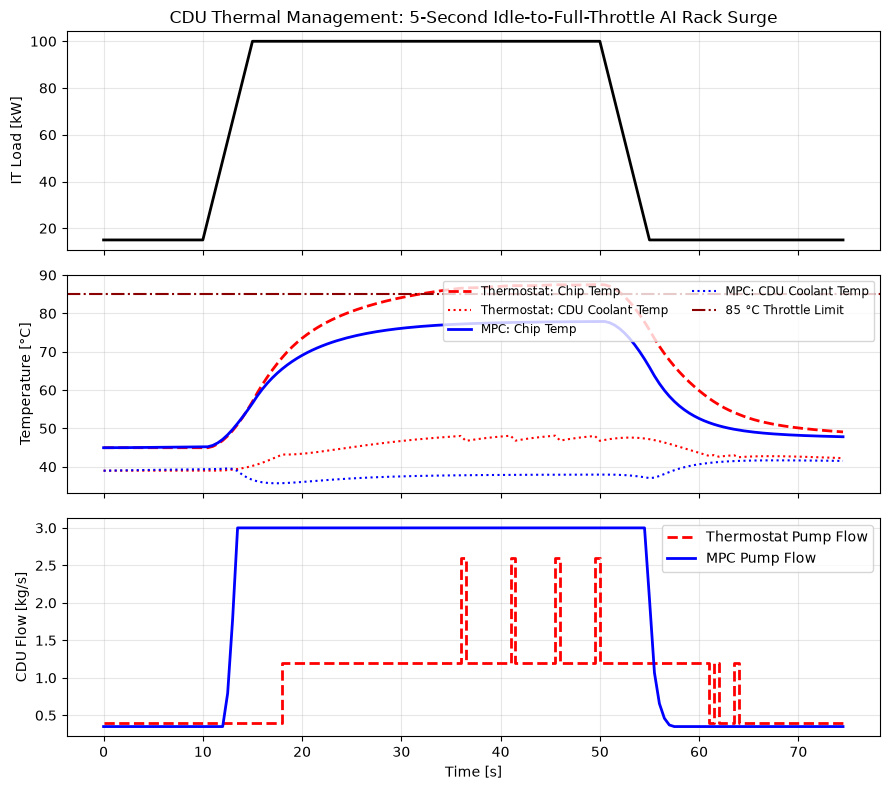

In [3]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Physical Parameters 
# ==============================================================================
C_chip = 12.0      # kJ/K  (silicon + copper cold plates)
C_cdu  = 35.0      # kJ/K  (~8.5 L secondary coolant + HX thermal mass)
R_th   = 0.40      # K/kW  (chip-to-coolant thermal resistance)
cp     = 4.18      # kJ/(kg*K) (water/glycol specific heat)
T_fac  = 30.0      # degC  (warm facility water supply, ASHRAE W3)
T_throttle = 85.0  # degC  (chip thermal throttling limit)
# T_soft_cap = 80.0  # degC  (MPC safety buffer below throttling)
T_soft_cap = 60.0  # degC  (MPC safety buffer below throttling)

m_min, m_max = 0.35, 3.0  # kg/s (CDU VFD pump flow rate bounds)

def cdu_ode(x, u_mdot, q_it):
    """Nonlinear 2-state CDU + cold-plate energy balance."""
    T_chip, T_cdu = x
    q_conv = (T_chip - T_cdu) / R_th
    dT_chip = (q_it - q_conv) / C_chip
    dT_cdu  = (q_conv - u_mdot * cp * (T_cdu - T_fac)) / C_cdu
    return np.array([dT_chip, dT_cdu])

def rk4_step(x, u, q_it, dt):
    """4th-order Runge-Kutta plant integration."""
    k1 = cdu_ode(x, u, q_it)
    k2 = cdu_ode(x + 0.5 * dt * k1, u, q_it)
    k3 = cdu_ode(x + 0.5 * dt * k2, u, q_it)
    k4 = cdu_ode(x + dt * k3, u, q_it)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# ==============================================================================
# 2. Simulation Setup 
# ==============================================================================
dt = 0.5
T_sim = 75.0
N_steps = int(T_sim / dt)
t_grid = np.arange(N_steps) * dt

# Idle steady state at Q_IT = 15 kW, m_dot = 0.4 kg/s
u_idle = 0.4
T_cdu0 = T_fac + 15.0 / (u_idle * cp)
T_chip0 = T_cdu0 + 15.0 * R_th
x0 = np.array([T_chip0, T_cdu0])

# Workload: 15 kW idle -> 100 kW full throttle in 5 seconds (t = 10s to 15s)
q_profile = np.zeros(N_steps)
for k, t in enumerate(t_grid):
    if t < 10.0:
        q_profile[k] = 15.0
    elif t < 15.0:
        q_profile[k] = 15.0 + 85.0 * (t - 10.0) / 5.0
    elif t < 50.0:
        q_profile[k] = 100.0
    elif t < 55.0:
        q_profile[k] = 100.0 - 85.0 * (t - 50.0) / 5.0
    else:
        q_profile[k] = 15.0

# ==============================================================================
# 3. Baseline: Classical 3-Stage Thermostat on CDU Coolant Temp (T_cdu)
# ==============================================================================
x_therm = x0.copy()
hist_therm = np.zeros((N_steps, 3))  # [T_chip, T_cdu, m_dot]

for k in range(N_steps):
    T_cdu_meas = x_therm[1]
#    if T_cdu_meas < 45.0:
    if T_cdu_meas < 43.0:
        u_curr = 0.4
#    elif T_cdu_meas < 52.0:
    elif T_cdu_meas < 48.0:
        u_curr = 1.2
    else:
        u_curr = 2.6
    hist_therm[k] = [x_therm[0], x_therm[1], u_curr]
    x_therm = rk4_step(x_therm, u_curr, q_profile[k], dt)

# ==============================================================================
# 4. Successive-Linearization MPC with Workload Feedforward (Q_IT)
# ==============================================================================
Np = 16  # 8-second prediction horizon (16 * 0.5 s)
x_mpc = x0.copy()
hist_mpc = np.zeros((N_steps, 3))
u_prev = u_idle

for k in range(N_steps):
    q_curr = q_profile[k]

    # Linearize continuous dynamics around current state & previous input
    f0 = cdu_ode(x_mpc, u_prev, q_curr)
    A_c = np.array([
        [-1.0 / (C_chip * R_th),  1.0 / (C_chip * R_th)],
        [ 1.0 / (C_cdu * R_th),  -(1.0 / (C_cdu * R_th) + u_prev * cp / C_cdu)]
    ])
    B_u = np.array([0.0, -cp * (x_mpc[1] - T_fac) / C_cdu])
    B_d = np.array([1.0 / C_chip, 0.0])
    c_0 = f0 - A_c @ x_mpc - B_u * u_prev - B_d * q_curr

    # Forward-Euler discrete matrices for fast horizon rollout
    Ad = np.eye(2) + dt * A_c
    Bu_d = dt * B_u
    Bd_d = dt * B_d
    cd_d = dt * c_0

    def mpc_objective(u_seq):
        x_pred = x_mpc.copy()
        cost = 0.0
        u_last = u_prev
        for j in range(Np):
            u_j = u_seq[j]
            # Roll out state with measured disturbance Q_IT held constant over horizon
            x_pred = Ad @ x_pred + Bu_d * u_j + Bd_d * q_curr + cd_d
            T_chip_pred = x_pred[0]

            # 1) Soft barrier against thermal throttling (penalize T_chip > 80 C)
            violation = max(0.0, T_chip_pred - T_soft_cap)
            cost += 100.0 * (violation ** 2)

            # 2) Pump affinity-law energy cost (P_pump proportional to flow^3)
            cost += 1.0 * (u_j ** 3)

            # 3) Pump slew-rate penalty for smooth VFD actuation
            cost += 3.0 * ((u_j - u_last) ** 2)
            u_last = u_j
        return cost

    res = minimize(
        mpc_objective,
        x0=np.full(Np, u_prev),
        method="L-BFGS-B",
        bounds=[(m_min, m_max)] * Np,
        options={"maxiter": 40}
    )
    u_opt = res.x[0]

    hist_mpc[k] = [x_mpc[0], x_mpc[1], u_opt]
    x_mpc = rk4_step(x_mpc, u_opt, q_curr, dt)
    u_prev = u_opt

# ==============================================================================
# 5. Summary Metrics & Comparison Plots
# ==============================================================================
print(f"Thermostat Peak T_chip: {hist_therm[:, 0].max():.2f} °C (Limit: {T_throttle} °C)")
print(f"Python MPC Peak T_chip: {hist_mpc[:, 0].max():.2f} °C (Limit: {T_throttle} °C)")

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)

axes[0].plot(t_grid, q_profile, "k-", lw=2)
axes[0].set_ylabel("IT Load [kW]")
axes[0].set_title("CDU Thermal Management: 5-Second Idle-to-Full-Throttle AI Rack Surge")
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_grid, hist_therm[:, 0], "r--", lw=2, label="Thermostat: Chip Temp")
axes[1].plot(t_grid, hist_therm[:, 1], "r:", lw=1.5, label="Thermostat: CDU Coolant Temp")
axes[1].plot(t_grid, hist_mpc[:, 0], "b-", lw=2, label="MPC: Chip Temp")
axes[1].plot(t_grid, hist_mpc[:, 1], "b:", lw=1.5, label="MPC: CDU Coolant Temp")
axes[1].axhline(T_throttle, color="darkred", linestyle="-.", lw=1.5, label="85 °C Throttle Limit")
axes[1].set_ylabel("Temperature [°C]")
axes[1].legend(loc="upper right", ncol=2, fontsize=8.5)
axes[1].grid(True, alpha=0.3)

axes[2].step(t_grid, hist_therm[:, 2], "r--", where="post", lw=2, label="Thermostat Pump Flow")
axes[2].plot(t_grid, hist_mpc[:, 2], "b-", lw=2, label="MPC Pump Flow")
axes[2].set_ylabel("CDU Flow [kg/s]")
axes[2].set_xlabel("Time [s]")
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusions

Instead of reacting blindly after a threshold is crossed like a classical thermostat, the controller embeds first-principles physics directly into its real-time decision loop. Here is how our controller works:

* **Physical laws as a forward simulator:** **Newton’s law of cooling** (expressed via thermal resistance $\dot{Q} = \Delta T / R_{\text{th}}$ and advective heat removal $\dot{m} c_p \Delta T$) tells the controller how much cooling a given pump speed can deliver, while **conservation of energy** ($C \frac{dT}{dt} = \dot{Q}_{\text{in}} - \dot{Q}_{\text{out}}$) accounts for thermal inertia. Together, they let the controller predict *ahead of time* whether a 5-second power surge will push the chip past its throttling limit before the bulk coolant temperature ever rises.
* **The loss (cost) function as engineering judgment:** Because there are infinitely many pump-speed trajectories that could keep the chip safe, the scalar objective function encodes your operational priorities—assigning a steep penalty to crossing the $80^\circ\text{C}$ safety buffer, a cubic penalty ($\dot{m}^3$) to reflect centrifugal pump electrical power, and a damping penalty to prevent pump hunting.
* **Optimization as automated "what-if" search:** At every sample step, the optimizer searches over feasible pump trajectories (respecting physical hardware limits $\dot{m}_{\min} \le \dot{m} \le \dot{m}_{\max}$) to find the sequence that minimizes that loss function.
* **Receding-horizon execution**. Even though the optimizer computes an entire sequence of future pump moves over the 8-second horizon, the controller **applies only the very first move**, discards the rest, measures the true temperatures and IT load at the next time step, updates its linearized model, and re-solves. That constant re-planning is what turns a physics-based optimizer into a true closed-loop feedback controller resilient to modeling approximations and sudden workload changes.

## Appendix

### 1. Time and Prediction-Horizon Indices

MPC distinguishes between **actual closed-loop time steps** and **internal look-ahead steps** simulated inside the optimizer:

| Symbol | Code Variable | Meaning & Values |
| --- | --- | --- |
| $k$ | `k` | **Current discrete sample index** ($k \in \{0, 1, \dots, N_{\text{steps}}-1\}$), corresponding to physical time $t_k = k\,\Delta t$. |
| $j$ | `j` | **Look-ahead step index** within the prediction horizon ($j \in \{0, 1, \dots, N_p - 1\}$). |
| $N_p$ | `Np` | **Prediction horizon length** in discrete steps ($N_p = 16$, which spans $16 \times 0.5\text{ s} = 8\text{ s}$ into the future). |
| $(\cdot)_{k+j \mid k}$ | — | **MPC conditional-prediction notation:** read as *"the predicted value of $(\cdot)$ at future step $k+j$, computed using measurements available at the current step $k$."* |

#### Boundary Conventions at $j = 0$

* **Initial state ($\mathbf{x}_{k \mid k} = \mathbf{x}_k$):** At $j = 0$, the prediction rollout starts from the actual measured system state $\mathbf{x}_k = [T_{\text{chip}}(t_k),\, T_{\text{cdu}}(t_k)]^T$ (`x_mpc`).
* **Previous control move ($u_{k-1 \mid k} \equiv u_{k-1}$):** When $j = 0$, the slew-rate term $(u_{k+j \mid k} - u_{k+j-1 \mid k})^2$ evaluates $(u_{k \mid k} - u_{k-1 \mid k})^2$. Here, $u_{k-1 \mid k}$ denotes the actual pump command applied during the previous interval $[t_{k-1}, t_k)$ (`u_prev`), anchoring the first control change to the pump's current operating speed.
* **Measured disturbance ($d_{k \mid k}$):** Represents the current IT heat load $Q_{\text{IT}}(t_k)$ (`q_curr`). Because future workload surges are assumed unknown in the baseline script, $d_{k \mid k}$ is held constant across all $j$ steps of the horizon (zero-order hold persistence).

---

### 2. Decision Variables and Objective Terms

* **$\mathbf{U}_k = \{u_{k \mid k}, u_{k+1 \mid k}, \dots, u_{k+N_p-1 \mid k}\}$ (`u_seq`):** The vector of $N_p$ candidate pump mass flow commands ($\text{kg/s}$) over which `scipy.optimize.minimize` searches. Once the optimal sequence $\mathbf{U}_k^*$ is found, only the first element $u_k^* = u_{k \mid k}^*$ is sent to the CDU pump.
* **$J(\mathbf{U}_k)$ (`cost`):** The scalar objective function (dimensionless) measuring total thermal risk, pumping energy, and actuator wear over the next $N_p$ steps.
* **$T_{\text{chip},\,k+j+1 \mid k}$ (`T_chip_pred`):** The first element ($x_{1,\,k+j+1 \mid k}$) of the predicted state vector $\mathbf{x}_{k+j+1 \mid k}$ in ${}^\circ\text{C}$. Notice the index is $k+j+1$ rather than $k+j$: applying pump flow $u_{k+j \mid k}$ during interval $[t_{k+j}, t_{k+j+1})$ determines the temperature at the *end* of that step, $t_{k+j+1}$. (At $j=0$, $T_{\text{chip},\,k \mid k}$ is already fixed by measurement and cannot be influenced by $\mathbf{U}_k$.)
* **$T_{\text{soft}}$ (`T_soft_cap`):** The soft upper temperature threshold ($80^\circ\text{C}$), set $5^\circ\text{C}$ below the hardware throttling limit $T_{\text{throttle}} = 85^\circ\text{C}$ to absorb plant-model mismatch and discretization error.
* **$\max(0, \; T_{\text{chip},\,k+j+1 \mid k} - T_{\text{soft}})$ (`violation`):** A one-sided hinge (rectified linear) function. It evaluates to $0$ whenever $T_{\text{chip}} \le 80^\circ\text{C}$—so the controller does not waste pump energy overcooling an idle rack—and becomes positive only when predicted temperature enters the $80\text{–}85^\circ\text{C}$ buffer zone.

---

### 3. Tuning Weights ($w_T$, $w_u$, $w_{\Delta u}$)

The three scalar weights balance competing physical objectives and carry inverse units so that every term summed into $J(\mathbf{U}_k)$ is dimensionless:

| Weight | Value in Code | Units | Physical Role & Tuning Logic |
| --- | --- | --- | --- |
| **$w_T$** | `100.0` | $[{}^\circ\text{C}^{-2}]$ | **Thermal violation penalty weight.** Set two orders of magnitude larger than $w_u$ so avoiding chip throttling overrides energy savings. Even a $1^\circ\text{C}$ excursion above $80^\circ\text{C}$ adds $100 \times 1^2 = 100$ to the cost, outweighing running the pump at full flow ($1.0 \times 3^3 = 27$). |
| **$w_u$** | `1.0` | $[(\text{kg/s})^{-3}]$ | **Pumping energy weight.** Multiplies $u^3$ because centrifugal pump shaft power scales with the cube of volumetric/mass flow rate ($P_{\text{pump}} \propto \dot{m}^3$) under the pump affinity laws. Pulls flow down toward $\dot{m}_{\min}$ whenever $T_{\text{chip}}$ is safely below $T_{\text{soft}}$. |
| **$w_{\Delta u}$** | `3.0` | $[(\text{kg/s})^{-2}]$ | **Move-suppression (slew-rate) weight.** Penalizes step-to-step changes $\Delta u = u_{k+j \mid k} - u_{k+j-1 \mid k}$ to prevent VFD pump hunting and hydraulic water-hammer transients. |

---

### 4. Dynamics and Actuator Constraints

* **Discrete-time equality constraint:**

$$\mathbf{x}_{k+j+1 \mid k} = A_d \mathbf{x}_{k+j \mid k} + \mathbf{B}_{u,d} u_{k+j \mid k} + \mathbf{B}_{d,d} d_{k \mid k} + \mathbf{c}_d$$



Enforces the linearized thermal energy balance at every look-ahead step $j$, where $A_d \in \mathbb{R}^{2 \times 2}$ (`Ad`), $\mathbf{B}_{u,d} \in \mathbb{R}^{2 \times 1}$ (`Bu_d`), $\mathbf{B}_{d,d} \in \mathbb{R}^{2 \times 1}$ (`Bd_d`), and $\mathbf{c}_d \in \mathbb{R}^2$ (`cd_d`) are recomputed at each step $k$ around $(\mathbf{x}_k, u_{k-1}, d_k)$.
* **Actuator box constraints ($\dot{m}_{\min} \le u_{k+j \mid k} \le \dot{m}_{\max}$):**
Restricts every planned pump flow command to the physical operating range of the CDU variable-speed pump (`m_min = 0.35 kg/s` to `m_max = 3.0 kg/s`), passed to `L-BFGS-B` via `bounds=[(m_min, m_max)] * Np`.
* **Universal quantifier ($\forall j \in \{0, \dots, N_p - 1\}$):**
Read as *"for all look-ahead steps $j$ from $0$ to $N_p - 1$,"* indicating that both the discrete state-update equation and the pump flow limits apply across every step of the prediction window.